# DSCI 552 | Homework 7
**Haresh Sambandamoorthy | Fall 2026**

All numerical results are computed from the supplied *Anuran Calls (MFCCs)* CSV. Sections 1 and 2 answer the required data questions. Section 3 answers **all five parts** of ISLR 12.6.2. The explicitly marked extra-practice questions are optional and are not required for the core homework.

**Reproducibility:** Run all cells in order from the project root. Random seeds are fixed. Hyperparameters are selected on training folds only, and the test partition is held out until evaluation. The clustering exercise correctly uses all observations.

## 1. Multi-class and multi-label classification using support vector machines
### 1(a) Data and random 70/30 split
Each observation has 22 MFCC features and three categorical labels: Family, Genus, Species. `RecordID` is an identifier, **not** a predictive feature.

In [1]:
from pathlib import Path
import json
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, hamming_loss, confusion_matrix,
                             precision_recall_fscore_support, calinski_harabasz_score,
                             silhouette_score)
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.exceptions import ConvergenceWarning
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore", category=ConvergenceWarning)
DATA_PATH = Path('data') / 'Frogs_MFCCs.csv'
RESULT_DIR = Path('results')
FIG_DIR = Path('figures')
RESULT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
LABELS = ['Family', 'Genus', 'Species']
df = pd.read_csv(DATA_PATH)
feature_cols = [col for col in df.columns if col.startswith('MFCCs_')]
assert len(feature_cols) == 22
assert df[feature_cols + LABELS].notna().all().all()
X = df[feature_cols].to_numpy(dtype=float)
Y = df[LABELS].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.30, random_state=SEED, shuffle=True)
print(f'Total: {len(df)} | Train: {len(X_train)} | Test: {len(X_test)}')
print('Feature count:',len(feature_cols), '| Label types:', {k: Y[k].nunique() for k in LABELS})
print('Missing values:',int(df.isna().sum().sum()))
for label in LABELS:
    print(label,'train counts:',y_train[label].value_counts().to_dict())

Total: 7195 | Train: 5036 | Test: 2159
Feature count: 22 | Label types: {'Family': 4, 'Genus': 8, 'Species': 10}
Missing values: 0
Family train counts: {'Leptodactylidae': 3073, 'Hylidae': 1542, 'Dendrobatidae': 380, 'Bufonidae': 41}
Genus train counts: {'Adenomera': 2899, 'Hypsiboas': 1125, 'Ameerega': 380, 'Dendropsophus': 226, 'Leptodactylus': 174, 'Scinax': 111, 'Osteocephalus': 80, 'Rhinella': 41}
Species train counts: {'AdenomeraHylaedactylus': 2447, 'HypsiboasCordobae': 788, 'AdenomeraAndre': 452, 'Ameeregatrivittata': 380, 'HypsiboasCinerascens': 337, 'HylaMinuta': 226, 'LeptodactylusFuscus': 174, 'ScinaxRuber': 111, 'OsteocephalusOophagus': 80, 'Rhinellagranulosa': 41}


### 1(b)(i) Exact match, Hamming distance, Hamming score and Hamming loss
- **Exact match:** fraction of calls for which **all three** label predictions are correct.
- **Hamming distance (per call):** the number of incorrect labels, 0 through 3. We report its average.
- **Hamming loss:** wrong label positions divided by all `n × 3` positions.
- **Hamming score (label-wise accuracy):** correct label positions divided by all `n × 3` positions, equal to `1 − Hamming loss`.

A different use of “Hamming score” defines a Jaccard score for sets of labels. Here we use the **per-label matching fraction** because the three targets each have exactly one class, and the task explicitly pairs Hamming score with Hamming loss.

In [2]:
def evaluate_triplets(y_true, y_pred):
    truth=np.asarray(y_true)
    predicted=np.asarray(y_pred)
    mismatches=(truth != predicted)
    return {'exact_match':float(np.mean(np.all(~mismatches,axis=1))),
            'hamming_distance':float(np.mean(np.sum(mismatches,axis=1))),
            'hamming_score':float(1.0-np.mean(mismatches)),
            'hamming_loss':float(np.mean(mismatches))}

def per_label_details(y_true, y_pred, approach):
    records=[]
    for col in LABELS:
        a=np.asarray(y_true[col]); b=np.asarray(y_pred[col])
        prec,rec,f1,_=precision_recall_fscore_support(a,b,average='macro',zero_division=0)
        records.append({'approach':approach,'label':col,'accuracy':accuracy_score(a,b),
                        'macro_precision':prec,'macro_recall':rec,'macro_f1':f1})
    return pd.DataFrame(records)

def summarize_models(predictions, truth=y_test):
    return pd.DataFrame([{'approach':name,**evaluate_triplets(truth.to_numpy(),yp.to_numpy())}
                         for name,yp in predictions.items()])

### 1(b)(ii) Gaussian (RBF) SVM, one-versus-rest, ten-fold cross-validation
Separate multi-class predictors are tuned for Family, Genus and Species. Each predictor uses one-vs-rest (`OneVsRestClassifier` wrapping `SVC`). A scaler is fitted **inside each training fold**; held-out folds and test data never determine the scaler. `gamma` controls inverse RBF width (`gamma = 1/(2σ²)`), while `C` controls the penalty for classification errors.

In [3]:
folds=StratifiedKFold(n_splits=10,shuffle=True,random_state=SEED)
rbf_grid={'model__estimator__C':[0.1,1.0,10.0,100.0],
          'model__estimator__gamma':[0.01,0.1,1.0]}
rbf_pred=pd.DataFrame(index=y_test.index)
rbf_models={}
cv_records=[]
with threadpool_limits(limits=1):
    for col in LABELS:
        pipeline=Pipeline([('scale',StandardScaler()),
                           ('model',OneVsRestClassifier(SVC(kernel='rbf')))])
        grid=GridSearchCV(pipeline,rbf_grid,cv=folds,scoring='accuracy',n_jobs=4,refit=True)
        grid.fit(X_train,y_train[col])
        rbf_models[col]=grid.best_estimator_
        rbf_pred[col]=grid.predict(X_test)
        cv_records.append({'approach':'RBF SVM','label':col,'cv_accuracy':grid.best_score_,
                           'C':grid.best_params_['model__estimator__C'],
                           'gamma':grid.best_params_['model__estimator__gamma']})
        print(f'{col}: C={grid.best_params_["model__estimator__C"]}, '
              f'gamma={grid.best_params_["model__estimator__gamma"]}, '
              f'CV accuracy={grid.best_score_:.4f}, test accuracy={accuracy_score(y_test[col],rbf_pred[col]):.4f}')
cv_rbf=pd.DataFrame(cv_records)
cv_rbf.to_csv(RESULT_DIR/'rbf_cv.csv',index=False)
print('RBF triplet scores:',evaluate_triplets(y_test.to_numpy(),rbf_pred.to_numpy()))

Family: C=10.0, gamma=0.1, CV accuracy=0.9905, test accuracy=0.9935


Genus: C=10.0, gamma=0.1, CV accuracy=0.9891, test accuracy=0.9884


Species: C=10.0, gamma=0.1, CV accuracy=0.9889, test accuracy=0.9880
RBF triplet scores: {'exact_match': 0.9865678554886521, 'hamming_distance': 0.030106530801296896, 'hamming_score': 0.9899644897329011, 'hamming_loss': 0.010035510267098965}


### 1(b)(iii) L1-penalized linear SVM, ten-fold cross-validation
The assignment notes that L1 regularization is conventionally used with a **linear kernel**. `LinearSVC(penalty='l1', dual=False)` uses one-vs-rest multi-class classification by default. Again the scaler is learned within training folds only.

In [4]:
l1_grid={'model__C':[0.001,0.01,0.1,1.0]}
l1_pred=pd.DataFrame(index=y_test.index)
l1_models={}
cv_records=[]
with threadpool_limits(limits=1):
    for col in LABELS:
        pipeline=Pipeline([('scale',StandardScaler()),
                           ('model',LinearSVC(penalty='l1',dual=False,
                                              max_iter=4000,tol=0.002,random_state=SEED))])
        grid=GridSearchCV(pipeline,l1_grid,cv=folds,scoring='accuracy',n_jobs=4,refit=True)
        grid.fit(X_train,y_train[col])
        l1_models[col]=grid.best_estimator_
        l1_pred[col]=grid.predict(X_test)
        cv_records.append({'approach':'L1 linear SVM','label':col,'cv_accuracy':grid.best_score_,
                           'C':grid.best_params_['model__C'],'gamma':np.nan})
        print(f'{col}: C={grid.best_params_["model__C"]}, '
              f'CV accuracy={grid.best_score_:.4f}, test accuracy={accuracy_score(y_test[col],l1_pred[col]):.4f}')
cv_l1=pd.DataFrame(cv_records)
cv_l1.to_csv(RESULT_DIR/'l1_cv.csv',index=False)
print('L1 triplet scores:',evaluate_triplets(y_test.to_numpy(),l1_pred.to_numpy()))

Family: C=1.0, CV accuracy=0.9404, test accuracy=0.9287


Genus: C=1.0, CV accuracy=0.9502, test accuracy=0.9412


Species: C=1.0, CV accuracy=0.9601, test accuracy=0.9588
L1 triplet scores: {'exact_match': 0.9147753589624826, 'hamming_distance': 0.1713756368689208, 'hamming_score': 0.9428747877103597, 'hamming_loss': 0.057125212289640265}


### 1(b)(iv) L1 SVM with SMOTE to reduce class imbalance
SMOTE makes extra training examples for minority classes by interpolating nearby members of the same class. To avoid creating an excessively large, fully equalized dataset, only classes below **25% of that fold's largest class** are oversampled to that threshold. `SMOTE(k_neighbors=3)` is inside the cross-validation pipeline after scaling, so validation examples are **never** used to generate synthetic training data. We repeat the same ten-fold penalty search.

In [5]:
def smote_targets(y):
    counts=pd.Series(y).value_counts()
    floor_count=int(np.ceil(0.25*counts.max()))
    return {class_name:floor_count for class_name,count in counts.items()
            if count < floor_count}

smote_pred=pd.DataFrame(index=y_test.index)
smote_models={}
cv_records=[]
with threadpool_limits(limits=1):
    for col in LABELS:
        pipeline=ImbPipeline([('scale',StandardScaler()),
                              ('smote',SMOTE(sampling_strategy=smote_targets,
                                             k_neighbors=3,random_state=SEED)),
                              ('model',LinearSVC(penalty='l1',dual=False,
                                                 max_iter=4000,tol=0.002,random_state=SEED))])
        grid=GridSearchCV(pipeline,l1_grid,cv=folds,scoring='accuracy',n_jobs=4,refit=True)
        grid.fit(X_train,y_train[col])
        smote_models[col]=grid.best_estimator_
        smote_pred[col]=grid.predict(X_test)
        cv_records.append({'approach':'L1 + SMOTE','label':col,'cv_accuracy':grid.best_score_,
                           'C':grid.best_params_['model__C'],'gamma':np.nan})
        print(f'{col}: C={grid.best_params_["model__C"]}, '
              f'CV accuracy={grid.best_score_:.4f}, test accuracy={accuracy_score(y_test[col],smote_pred[col]):.4f}')
cv_smote=pd.DataFrame(cv_records)
cv_smote.to_csv(RESULT_DIR/'smote_cv.csv',index=False)
print('SMOTE triplet scores:',evaluate_triplets(y_test.to_numpy(),smote_pred.to_numpy()))

Family: C=1.0, CV accuracy=0.9329, test accuracy=0.9217


Genus: C=0.1, CV accuracy=0.9438, test accuracy=0.9384


Species: C=1.0, CV accuracy=0.9589, test accuracy=0.9588
SMOTE triplet scores: {'exact_match': 0.9013432144511347, 'hamming_distance': 0.18110236220472442, 'hamming_score': 0.9396325459317585, 'hamming_loss': 0.06036745406824147}


### 1(b) Results and conclusions
Each table below uses the untouched 30% test set. Accuracy, precision, recall and F1 for each individual target are shown along with exact match and Hamming measures for all three targets jointly. The next cell saves the CSVs and a two-color comparison chart.

In [6]:
predictions={'RBF SVM':rbf_pred,'L1 linear SVM':l1_pred,'L1 + SMOTE':smote_pred}
cv_results=pd.concat([cv_rbf,cv_l1,cv_smote],ignore_index=True)
model_summary=summarize_models(predictions)
label_results=pd.concat([per_label_details(y_test,pred,name) for name,pred in predictions.items()],
                        ignore_index=True)
cv_results.to_csv(RESULT_DIR/'all_cv_parameters.csv',index=False)
model_summary.to_csv(RESULT_DIR/'classification_summary.csv',index=False)
label_results.to_csv(RESULT_DIR/'classification_by_label.csv',index=False)
print('Test triplet results:')
print(model_summary.to_string(index=False,float_format=lambda n:f'{n:.5f}'))
print('Per-label results:')
print(label_results.to_string(index=False,float_format=lambda n:f'{n:.5f}'))
fig,ax=plt.subplots(figsize=(7.5,3.6))
pos=np.arange(len(model_summary));w=0.34
ax.bar(pos-w/2,model_summary['exact_match'],w,color='#2D5786',label='Exact match')
ax.bar(pos+w/2,model_summary['hamming_score'],w,color='#BA6C46',edgecolor='white',label='Hamming score')
ax.set_xticks(pos,model_summary['approach']);ax.set_ylim(0,1.08);ax.set_ylabel('Fraction correct')
ax.legend(loc='lower left');ax.grid(axis='y',alpha=0.25)
for bars in ax.containers:
    ax.bar_label(bars,fmt='%.3f',padding=3,fontsize=9)
fig.tight_layout();fig.savefig(FIG_DIR/'classification_comparison.png',dpi=180);plt.close(fig)

for name,pred in predictions.items():
    for col in LABELS:
        cls=sorted(Y[col].unique())
        mat=confusion_matrix(y_test[col],pred[col],labels=cls)
        pd.DataFrame(mat,index=cls,columns=cls).to_csv(
            RESULT_DIR/f'confusion_{name.lower().replace(" ","_").replace("+","plus")}_{col.lower()}.csv')

cv_best=cv_results.sort_values('cv_accuracy',ascending=False).groupby('label').head(1)
print('CV-selected best approach per label (for illustration only):',cv_best.to_string(index=False))

Test triplet results:
     approach  exact_match  hamming_distance  hamming_score  hamming_loss
      RBF SVM      0.98657           0.03011        0.98996       0.01004
L1 linear SVM      0.91478           0.17138        0.94287       0.05713
   L1 + SMOTE      0.90134           0.18110        0.93963       0.06037
Per-label results:
     approach   label  accuracy  macro_precision  macro_recall  macro_f1
      RBF SVM  Family   0.99352          0.99470       0.96996   0.98149
      RBF SVM   Genus   0.98842          0.98459       0.95137   0.96714
      RBF SVM Species   0.98796          0.97798       0.96058   0.96894
L1 linear SVM  Family   0.92867          0.67597       0.69041   0.68308
L1 linear SVM   Genus   0.94118          0.93121       0.76215   0.80569
L1 linear SVM Species   0.95878          0.92990       0.88425   0.90292
   L1 + SMOTE  Family   0.92172          0.77404       0.91129   0.81905
   L1 + SMOTE   Genus   0.93840          0.83536       0.89767   0.85931
   L1 

CV-selected best approach per label (for illustration only): approach   label  cv_accuracy    C  gamma
 RBF SVM  Family     0.990468 10.0    0.1
 RBF SVM   Genus     0.989078 10.0    0.1
 RBF SVM Species     0.988880 10.0    0.1


**Held-out classification metrics**

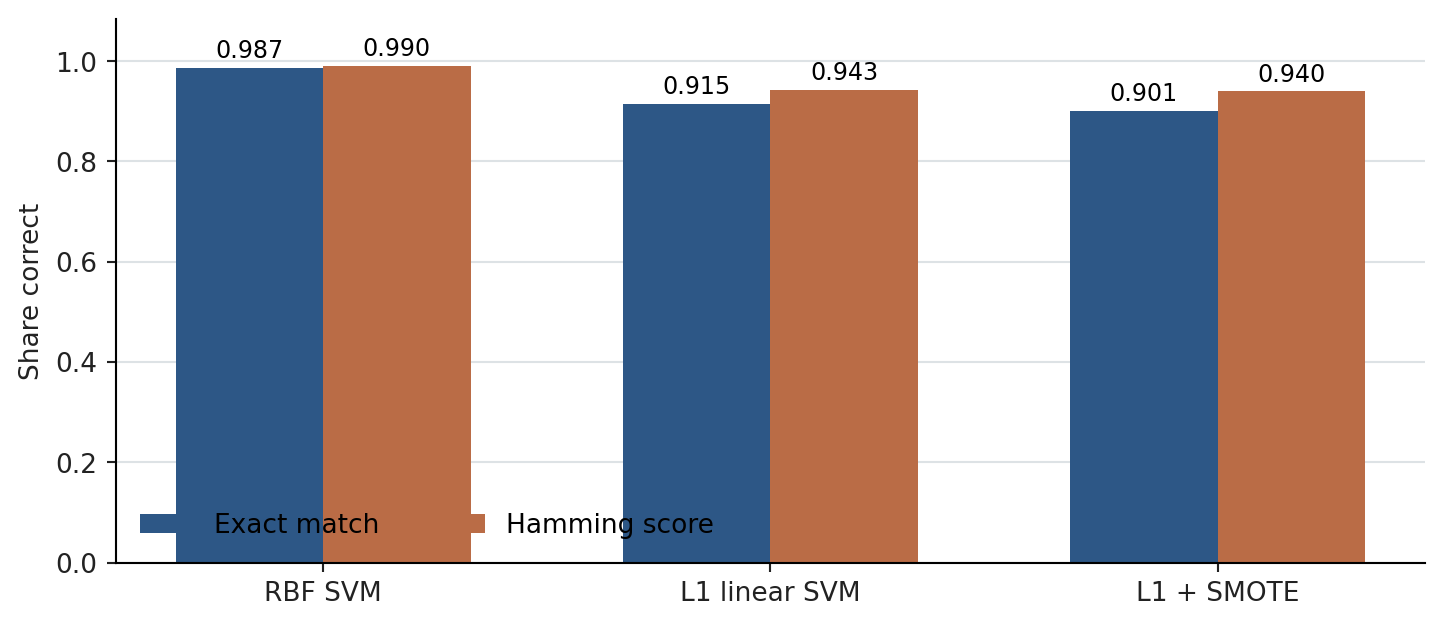

## 2. K-means clustering on the entire dataset
### 2(a) Automatic k selection across 50 Monte Carlo runs
For **each** of 50 independent random seeds, we fit K-means on **all 7,195 records** for each candidate `k` from 2 through 50. We choose the `k` with the highest *silhouette* score, estimated on a repeatable random sample of 500 observations to keep this 50-run exercise practical. Silhouette is undefined for `k=1`, so this candidate cannot be selected by that criterion. After selection, a final K-means fit uses the **whole data** and ten restarts (`n_init=10`) for stable centroids.

Feature scaling here uses the **whole dataset**, appropriately because this part has no train/test split or supervised evaluation.

In [7]:
X_cluster=StandardScaler().fit_transform(X)

def cluster_majority_triplets(cluster_ids,truth):
    # Independent majority vote for each of the three target columns.
    out=pd.DataFrame(index=truth.index,columns=LABELS)
    majority={}
    for cluster in np.unique(cluster_ids):
        mask=(cluster_ids==cluster)
        major=truth.iloc[np.flatnonzero(mask)][LABELS].mode(dropna=True).iloc[0]
        majority[int(cluster)]=major.to_dict()
        out.iloc[np.flatnonzero(mask)]=major.values
    return out,majority

cluster_records=[]
selected_k_records=[]
with threadpool_limits(limits=1):
    for run in range(50):
        seed=1000+run
        k_scores=[]
        # Each candidate model is fit to the whole data; only silhouette evaluation is sampled.
        for k in range(2,51):
            candidate=KMeans(n_clusters=k,random_state=seed,n_init=1,max_iter=120,
                             algorithm='lloyd')
            cand_labels=candidate.fit_predict(X_cluster)
            score=silhouette_score(X_cluster,cand_labels,sample_size=500,random_state=seed)
            k_scores.append((k,float(score)))
        chosen_k,best_score=max(k_scores,key=lambda pair:pair[1])
        fitted=KMeans(n_clusters=chosen_k,random_state=seed,n_init=10,max_iter=300,
                      algorithm='lloyd')
        clusters=fitted.fit_predict(X_cluster)
        predicted,majorities=cluster_majority_triplets(clusters,Y.reset_index(drop=True))
        result=evaluate_triplets(Y.to_numpy(),predicted.to_numpy())
        cluster_records.append({'run':run+1,'random_seed':seed,'selected_k':chosen_k,
                               'selection_silhouette':best_score,**result})
        for k,score in k_scores:
            selected_k_records.append({'run':run+1,'k':k,'sampled_silhouette':score})
        if (run+1)%10==0:
            print(f'Completed {run+1}/50 runs')
cluster_runs=pd.DataFrame(cluster_records)
cluster_scores=pd.DataFrame(selected_k_records)
cluster_runs.to_csv(RESULT_DIR/'clustering_50_runs.csv',index=False)
cluster_scores.to_csv(RESULT_DIR/'clustering_k_selection_scores.csv',index=False)
cluster_stats=cluster_runs[['hamming_distance','hamming_score','hamming_loss',
                            'exact_match','selected_k','selection_silhouette']].agg(['mean','std'])
cluster_stats.to_csv(RESULT_DIR/'clustering_summary_stats.csv')
print('Monte Carlo mean and sample standard deviation:',cluster_stats.to_string(float_format=lambda n:f'{n:.5f}'))
print('Distribution of selected k:',cluster_runs['selected_k'].value_counts().sort_index().to_string())

Completed 10/50 runs


Completed 20/50 runs


Completed 30/50 runs


Completed 40/50 runs


Completed 50/50 runs
Monte Carlo mean and sample standard deviation:       hamming_distance  hamming_score  hamming_loss  exact_match  selected_k  selection_silhouette
mean           0.78606        0.73798       0.26202      0.70333     3.52000               0.34401
std            0.09620        0.03207       0.03207      0.04251     1.18218               0.01428
Distribution of selected k: selected_k
2     8
3    20
4    16
5     2
6     2
7     2


### 2(b) Majority family, genus and species for every cluster
The majority is determined separately for each of the three true columns. The table below shows the majority triplets for the **first run**, including each cluster's size; the 50-run evaluation uses the same procedure separately in every run.

In [8]:
first_k=int(cluster_runs.loc[0,'selected_k'])
first_cluster_labels=KMeans(n_clusters=first_k,random_state=1000,n_init=10,max_iter=300,
                            algorithm='lloyd').fit_predict(X_cluster)
first_predictions,first_majorities=cluster_majority_triplets(first_cluster_labels,Y.reset_index(drop=True))
first_majority_rows=[{'cluster':idx,'size':int(np.sum(first_cluster_labels==idx)),**labels}
                     for idx,labels in first_majorities.items()]
first_majority_table=pd.DataFrame(first_majority_rows).sort_values('cluster')
first_majority_table.to_csv(RESULT_DIR/'first_run_majority_triplets.csv',index=False)
print(first_majority_table.to_string(index=False))

 cluster  size          Family     Genus                Species
       0   626         Hylidae Hypsiboas   HypsiboasCinerascens
       1  3574 Leptodactylidae Adenomera AdenomeraHylaedactylus
       2  2995         Hylidae Hypsiboas      HypsiboasCordobae


### 2(c) Average Hamming distance, Hamming score and Hamming loss
Because every call has exactly three label positions, for **each** run: `distance = 3 × loss` and `score = 1 − loss`. The following figure summarizes the Monte Carlo distribution and selected k values.

In [9]:
fig,ax=plt.subplots(figsize=(8.0,3.5))
ax.hist(cluster_runs['hamming_distance'],bins=12,color='#2C807B',edgecolor='white')
ax.axvline(cluster_runs['hamming_distance'].mean(),color='#BA6C46',linestyle='--',label='Mean')
ax.set_xlabel('Average Hamming distance per call');ax.set_ylabel('Number of runs');ax.legend()
fig.tight_layout();fig.savefig(FIG_DIR/'kmeans_distance_histogram.png',dpi=180);plt.close(fig)
fig,ax=plt.subplots(figsize=(7.5,3.5))
k_freq=cluster_runs['selected_k'].value_counts().sort_index()
ax.bar(k_freq.index,k_freq.values,color='#2D5786',edgecolor='white')
ax.set_xlabel('Automatically selected k');ax.set_ylabel('Number of runs');ax.set_xticks(k_freq.index)
fig.tight_layout();fig.savefig(FIG_DIR/'kmeans_k_frequency.png',dpi=180);plt.close(fig)
print('Sanity check: max distance-loss difference =',
      float(np.max(np.abs(cluster_runs['hamming_distance']-3*cluster_runs['hamming_loss']))))
print('Sanity check: max score-loss difference =',
      float(np.max(np.abs(cluster_runs['hamming_score']+cluster_runs['hamming_loss']-1))))

Sanity check: max distance-loss difference = 1.1102230246251565e-16
Sanity check: max score-loss difference = 0.0


**Automatically selected k in 50 runs**

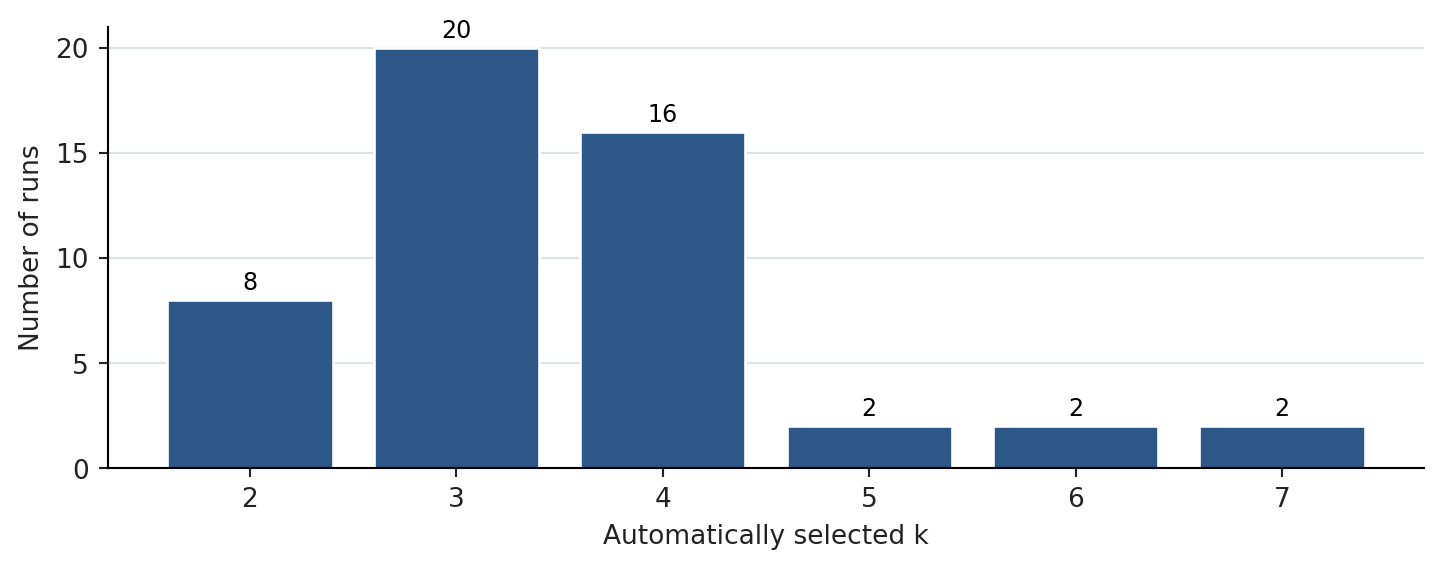

**Hamming-distance distribution across 50 runs**

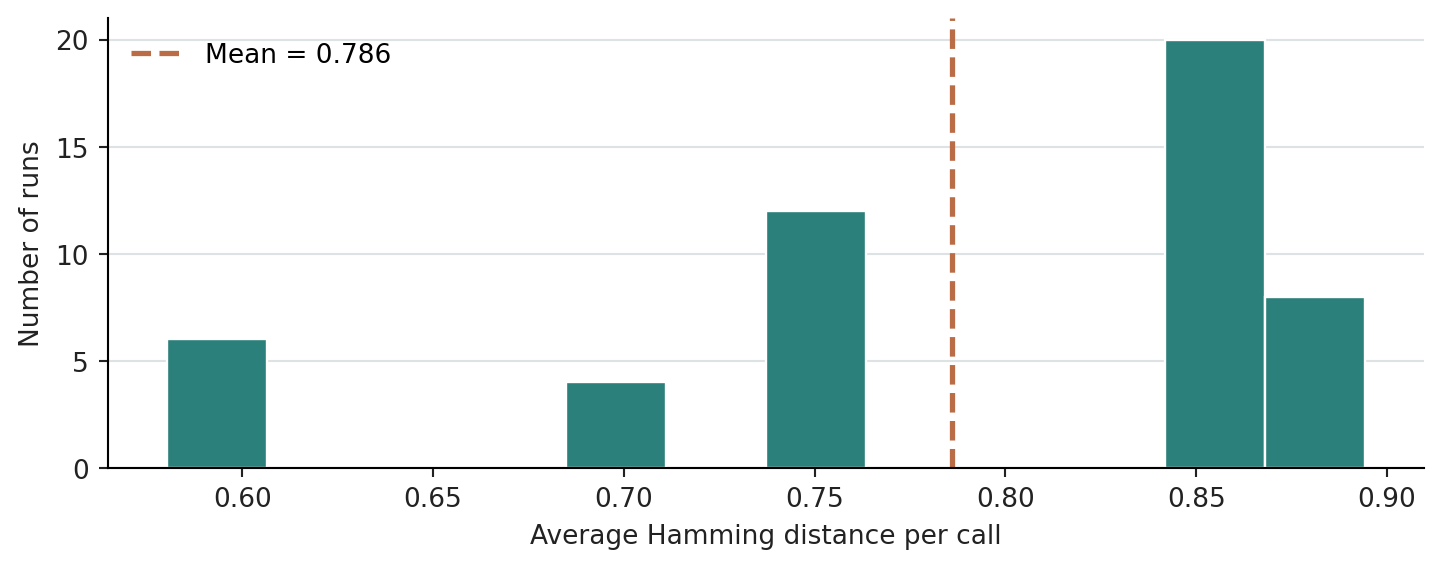

## 3. ISLR 12.6.2 - Hierarchical clustering
The second-edition ISLR exercise gives four observations and the following dissimilarities:

| Pair | 1–2 | 1–3 | 1–4 | 2–3 | 2–4 | 3–4 |
|---|---:|---:|---:|---:|---:|---:|
| Dissimilarity | 0.30 | 0.40 | 0.70 | 0.50 | 0.80 | 0.45 |

We solve every part (a) through (e) and save the dendrograms.

In [10]:
D=np.array([[0,.30,.40,.70],
            [.30,0,.50,.80],
            [.40,.50,0,.45],
            [.70,.80,.45,0]],dtype=float)
assert np.allclose(D,D.T)
z_complete=linkage(squareform(D),method='complete')
z_single=linkage(squareform(D),method='single')
print('Complete linkage: (cluster1, cluster2, height, new size)',z_complete)
print('Single linkage:',z_single)

def plot_dendrogram(Z,title,path,labels=None):
    fig,ax=plt.subplots(figsize=(6.8,3.5))
    dendrogram(Z,ax=ax,labels=labels or ['1','2','3','4'],color_threshold=0,
               above_threshold_color='#2D5786',link_color_func=lambda _: '#2D5786')
    ax.set_title(title);ax.set_xlabel('Observation');ax.set_ylabel('Dissimilarity (fusion height)')
    ax.set_ylim(0,0.88);ax.grid(axis='y',alpha=0.25)
    fig.tight_layout();fig.savefig(FIG_DIR/path,dpi=190);plt.close(fig)

plot_dendrogram(z_complete,'(a) Complete linkage','islr_complete_dendrogram.png')
plot_dendrogram(z_single,'(b) Single linkage','islr_single_dendrogram.png')

c_complete=fcluster(z_complete,2,criterion='maxclust')
c_single=fcluster(z_single,2,criterion='maxclust')
def group_members(labels):
    return [tuple(np.flatnonzero(labels==cluster)+1) for cluster in sorted(set(labels))]
print('(c) Two complete-linkage groups:',group_members(c_complete))
print('(d) Two single-linkage groups:',group_members(c_single))

# (e): Swap the leaves within BOTH final subtrees, while preserving branch heights.
# The complete linkage (1,2) pair and (3,4) pair are unchanged as sets.
from scipy.cluster.hierarchy import to_tree
root=to_tree(z_complete)
root.left.left,root.left.right = root.left.right,root.left.left
root.right.left,root.right.right = root.right.right,root.right.left
fig,ax=plt.subplots(figsize=(6.8,3.5))
def draw_tree(node,positions,ax):
    if node.is_leaf():return positions[node.id],0
    x1,y1=draw_tree(node.left,positions,ax);x2,y2=draw_tree(node.right,positions,ax)
    ax.plot([x1,x1,x2,x2],[y1,node.dist,node.dist,y2],color='#2D5786',lw=1.5)
    return (x1+x2)/2,node.dist
leaf_order=[1,0,3,2]
xpos={leaf:5+10*i for i,leaf in enumerate(leaf_order)}
draw_tree(root,xpos,ax)
ax.set_xticks([xpos[i] for i in leaf_order], [str(i+1) for i in leaf_order])
ax.set_xlim(0,40);ax.set_ylim(0,0.88)
ax.set_xlabel('Observation');ax.set_ylabel('Dissimilarity (fusion height)')
ax.set_title('(e) Equivalent complete-linkage tree, leaves swapped')
ax.grid(axis='y',alpha=.25);fig.tight_layout()
fig.savefig(FIG_DIR/'islr_equivalent_dendrogram.png',dpi=190);plt.close(fig)
print('(e) Equivalent leaf order:',[i+1 for i in leaf_order])
print('Complete merge heights:',z_complete[:,2].tolist())
print('Single merge heights:',z_single[:,2].tolist())

Complete linkage: (cluster1, cluster2, height, new size) [[0.   1.   0.3  2.  ]
 [2.   3.   0.45 2.  ]
 [4.   5.   0.8  4.  ]]
Single linkage: [[0.   1.   0.3  2.  ]
 [2.   4.   0.4  3.  ]
 [3.   5.   0.45 4.  ]]


(c) Two complete-linkage groups: [(np.int64(1), np.int64(2)), (np.int64(3), np.int64(4))]
(d) Two single-linkage groups: [(np.int64(1), np.int64(2), np.int64(3)), (np.int64(4),)]


(e) Equivalent leaf order: [2, 1, 4, 3]
Complete merge heights: [0.3, 0.45, 0.8]
Single merge heights: [0.3, 0.4, 0.45]


**3(a) Complete-linkage dendrogram**

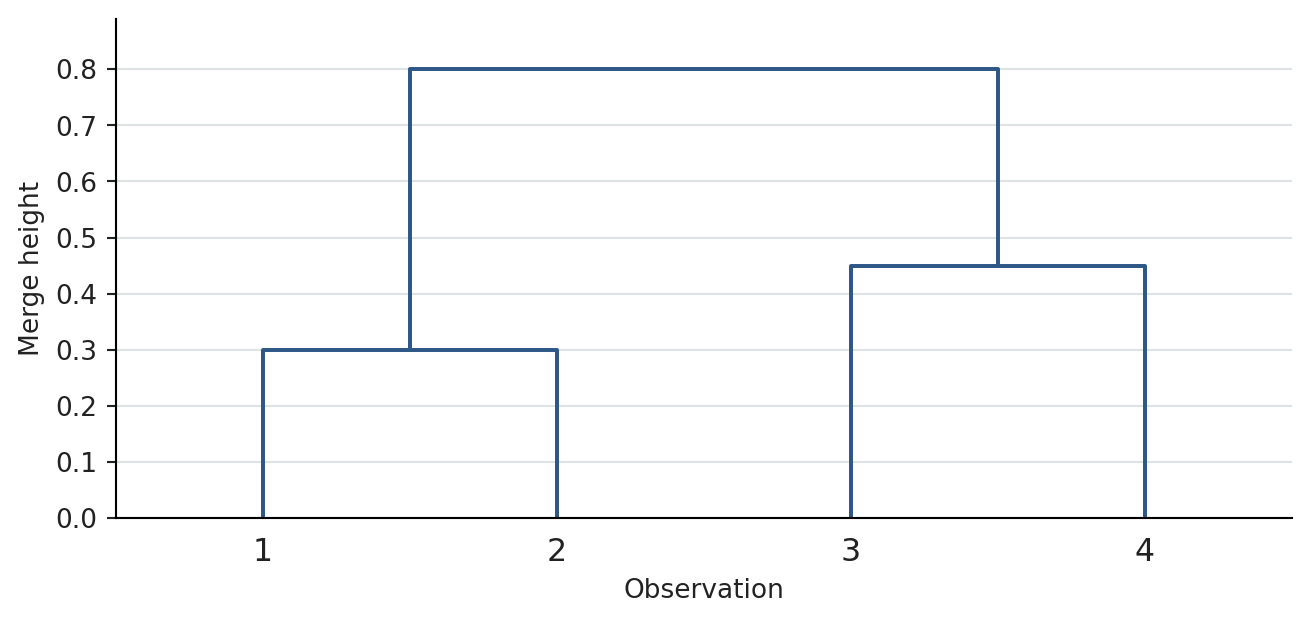

**3(b) Single-linkage dendrogram**

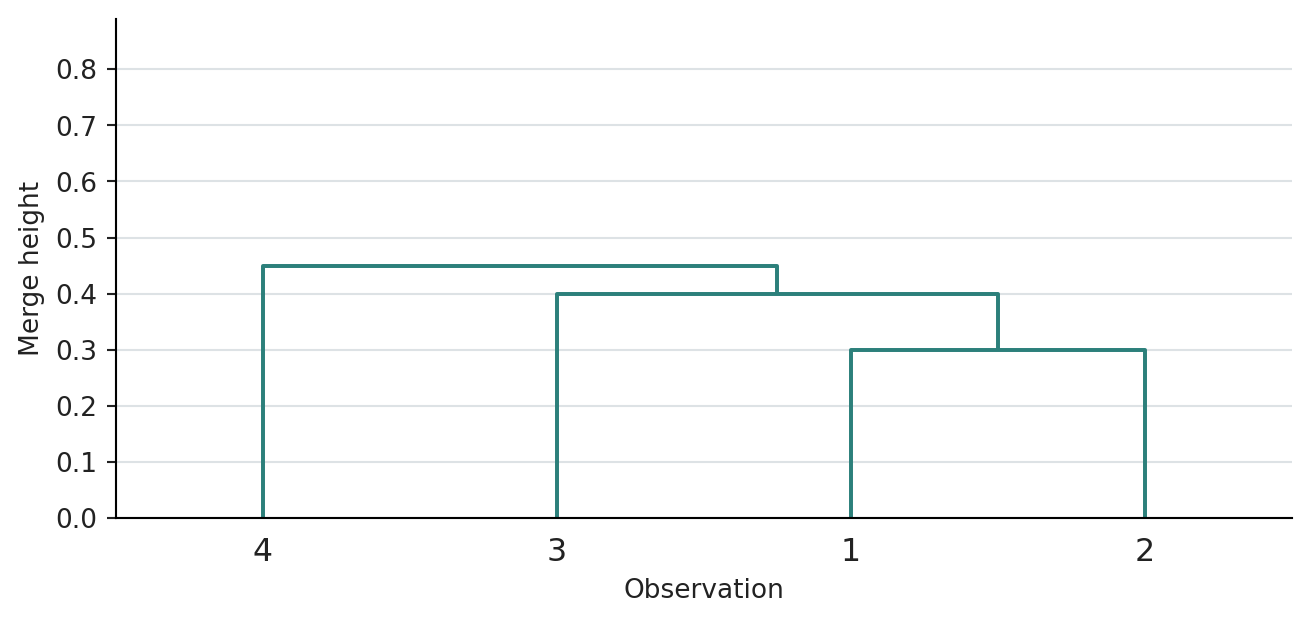

**3(e) Equivalent complete-linkage dendrogram**

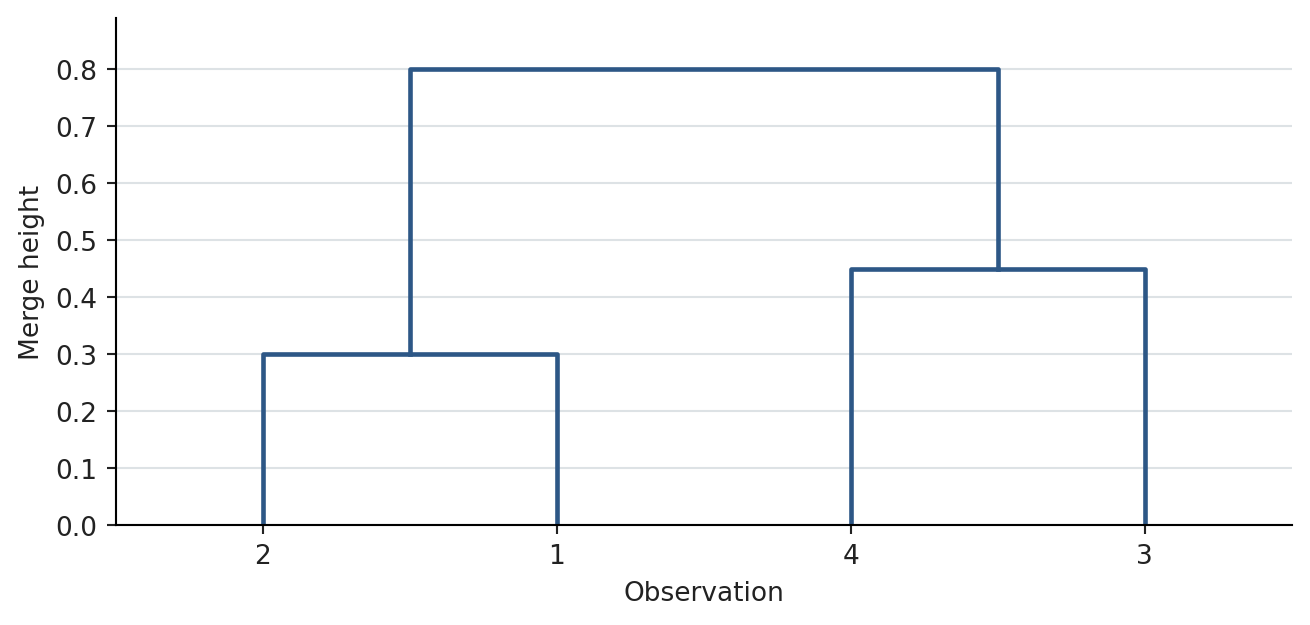

### 3(a)–(e) Written answers
**(a)** Complete linkage merges observations **1 and 2 at 0.30**, then **3 and 4 at 0.45**. The two pairs merge at height **0.80**, the largest between-pair distance.

**(b)** Single linkage merges **1 and 2 at 0.30**, then **3 joins {1,2} at 0.40** (the smallest link is d(1,3)=0.40), then **4 joins at 0.45** (d(3,4)=0.45).

**(c)** Cutting the complete-linkage dendrogram to two clusters gives **{1,2}** and **{3,4}**.

**(d)** Cutting the single-linkage dendrogram to two clusters gives **{1,2,3}** and **{4}**.

**(e)** Swapping the order of leaves **1 and 2**, and also leaves **3 and 4**, leaves the complete-linkage hierarchy and all three fusion heights unchanged. The third plotted dendrogram shows this equivalent display.

## References and AI use acknowledgment
1. DSCI 552, *Homework 7*, provided assignment instructions and *Anuran Calls (MFCCs)* dataset ZIP.
2. UCI Machine Learning Repository, *Anuran Calls (MFCCs)*: https://archive.ics.uci.edu/dataset/406/anuran+calls+mfccs
3. Gareth James, Daniela Witten, Trevor Hastie and Robert Tibshirani, *An Introduction to Statistical Learning*, second edition, Chapter 12, Exercise 12.6.2: https://www.statlearning.com/
4. scikit-learn documentation, `SVC`, `OneVsRestClassifier`, `LinearSVC`, `GridSearchCV`, `KMeans`, `silhouette_score`: https://scikit-learn.org/stable/
5. imbalanced-learn documentation, `SMOTE` and `Pipeline`: https://imbalanced-learn.org/stable/

**AI use acknowledgment:** AI tools were used to assist with organizing the code, compiling the report, and checking formatting. Numerical results are generated from the supplied dataset by the accompanying reproducible code.

**Scope note:** Sections 1(b)(v)-(vi) and 4 are explicitly labeled **Extra Practice** in the assignment. The core requirements, 1(a)-(b)(iv), 2(a)-(c) and 3(a)-(e), are answered here.